In [1]:
#Importing Data Libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import kagglehub # May need to install this package if not already installed (pip install kagglehub)
import os
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [2]:
path = kagglehub.dataset_download("dillonmyrick/bells-palsy-clinical-trial")
files = os.listdir(path) # Lists files

csv_file = [f for f in files if f.endswith('.csv')][0] # Find the first file that ends in .csv
csv_path = os.path.join(path, csv_file) # Join path and CSV file

df = pd.read_csv(csv_path)

100%|██████████| 3.63k/3.63k [00:00<00:00, 5.99MB/s]

Extracting files...


In [3]:
#Data Cleaning and Scaling
#df = pd.read_csv("Bells Palsy Clinical Trial.csv")

#Changing Sex to dummy variables, Male = 1, Female = 0
df["Sex"]= (df["Sex"] == "Male").astype(int)

#Changing Within 24 hr to 0, >24 to ≤48 hr to 1, >48 to ≤72 hr to 2, REMOVED the Unknown
df["Time between onset of symptoms and start of treatment"] = df["Time between onset of symptoms and start of treatment"].map({"Within 24 hr": 0, ">24 to ≤48 hr": 1, ">48 to ≤72 hr": 2})


#Changing Received Prednisolone to No = 0, Yes = 1 and Received Acyclovir to No = 0, Yes = 1
df["Received Prednisolone"] = df["Received Prednisolone"].map({"Yes": 1, "No": 0})
df["Received Acyclovir"] = df["Received Acyclovir"].map({"Yes": 1, "No": 0})

#Changing Full Recovery in 3 months to No = 0, Yes = 1 and Full Recovery in 9 months to No = 0, Yes = 1
df["Full Recovery in 3 Months"] = df["Full Recovery in 3 Months"].map({"No": 0, "Yes": 1})
df["Full Recovery in 9 Months"] = df["Full Recovery in 9 Months"].map({"No": 0, "Yes": 1})

#Dropping Treatment Group since its the same as received prednislone/acyclovir
df= df.drop("Treatment Group", axis = 1)

#Convert to floats
df["Time between onset of symptoms and start of treatment"] = df["Time between onset of symptoms and start of treatment"].astype("Int64") # supports missing values
df["Received Prednisolone"] = df["Received Prednisolone"].astype(int)
df["Received Acyclovir"] = df["Received Acyclovir"].astype(int)
df["Full Recovery in 3 Months"] = df["Full Recovery in 3 Months"].astype(int)
df["Full Recovery in 9 Months"] = df["Full Recovery in 9 Months"].astype(int)

#Drop NA Rows
df = df.dropna()

# Features and Target Variables
x = df[["Sex", "Age", "Baseline Score on House–Brackmann scale", "Time between onset of symptoms and start of treatment", "Received Prednisolone", "Received Acyclovir"]]

y_3month_score = df["3-Month Score on House–Brackmann scale"]
y_3month_recovery = df["Full Recovery in 3 Months"]
y_9month_score = df["9-Month Score on House–Brackmann scale"]
y_9month_recovery = df["Full Recovery in 9 Months"]

#Standardize the Features
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)


Silhouette Scores for KMeans Clustering:
K=2: 0.177
K=3: 0.157
K=4: 0.135
K=5: 0.189
K=6: 0.179
K=7: 0.170
K=8: 0.193
K=9: 0.206


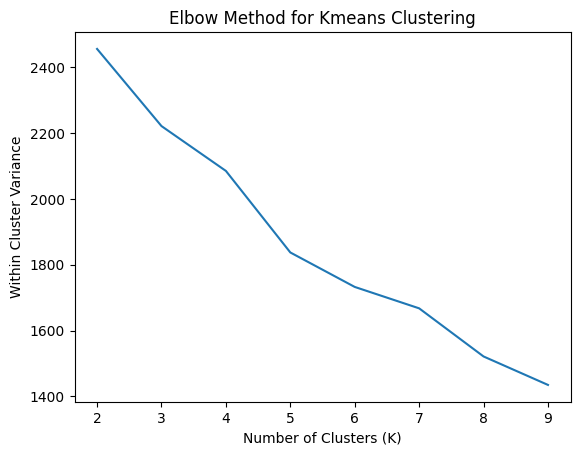

In [4]:
#Applying Elbow Method and Determining Silhouette Score for KMeans Clustering
from sklearn.metrics import silhouette_score
Within_Cluster = []
Iterations = 10
Silhouette_Scores = []
for k in range(2, Iterations):
    kmeans = KMeans(n_clusters = k, init = 'k-means++', random_state = 5) #Uses (init)ialization = kmeans++ to avoid random initialization, thereby improving convergence
    kmeans.fit(x_scaled)
    Within_Cluster.append(kmeans.inertia_)
    predictions = kmeans.predict(x_scaled)
    silhouette = silhouette_score(x_scaled, predictions)
    Silhouette_Scores.append(silhouette)

print(f"Silhouette Scores for KMeans Clustering:" )
for i, score in enumerate(Silhouette_Scores):
    print(f"K={i+2}: {score:.3f}")
plt.plot(range(2, Iterations), Within_Cluster)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within Cluster Variance")
plt.title("Elbow Method for Kmeans Clustering")
plt.show()

Variance Ratio of PC1: 20.96%
Variance Ratio of PC2: 17.69%
Total Variance Explained by PC1 and PC2: 38.65%
Baseline Score on House–Brackmann scale         2         3         4  \
cluster                                                                 
0                                        0.006803  0.088435  0.380952   
1                                        0.224138  0.321839  0.350575   
2                                        0.255814  0.383721  0.261628   

Baseline Score on House–Brackmann scale         5         6  
cluster                                                      
0                                        0.306122  0.217687  
1                                        0.097701  0.005747  
2                                        0.098837  0.000000  
3-Month Score on House–Brackmann scale         1         2         3         4
cluster                                                                       
0                                       0.551020  0.326531

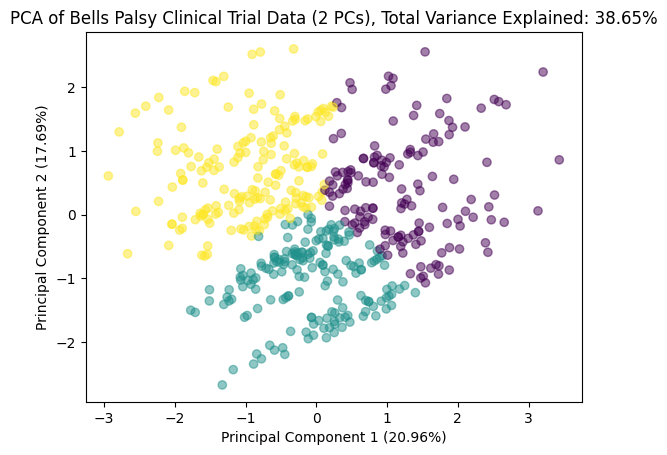

In [5]:
#PCa and KMeans Clustering with 2 Principal Components
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)

kmeans = KMeans(n_clusters = 3, init = 'k-means++', random_state = 3)
labels = kmeans.fit_predict(x_pca)

variance_ratio = pca.explained_variance_ratio_
print(f"Variance Ratio of PC1: {variance_ratio[0]*100:.2f}%")
print(f"Variance Ratio of PC2: {variance_ratio[1]*100:.2f}%")
total_variance = (variance_ratio[0] + variance_ratio[1]) * 100
print(f"Total Variance Explained by PC1 and PC2: {total_variance:.2f}%")

#Plotting the Clusters
plt.figure()
plt.scatter(x_pca[:, 0], x_pca[:, 1], c=labels, cmap='viridis', alpha=0.5)
plt.xlabel(f'Principal Component 1 ({variance_ratio[0]*100:.2f}%)')
plt.ylabel(f'Principal Component 2 ({variance_ratio[1]*100:.2f}%)')
plt.title("PCA of Bells Palsy Clinical Trial Data (2 PCs), Total Variance Explained: {:.2f}%".format(total_variance))

#Analyzing the Cluster Characteristics with the 3-month and 9-month scores on the House–Brackmann scale
df['cluster'] = labels
print("===============================================")
print(pd.crosstab(df['cluster'], df['Baseline Score on House–Brackmann scale'], normalize='index'))
print("===============================================")
print(pd.crosstab(df['cluster'], df['3-Month Score on House–Brackmann scale'], normalize='index'))
print("===============================================")
print(pd.crosstab(df['cluster'], df['9-Month Score on House–Brackmann scale'], normalize='index'))



In [6]:
#Summary for PCA and KMeans Clustering with 2 Principal Components: each cluster
pred = pd.crosstab(df['cluster'], df['Received Prednisolone'], normalize='index')
acy = pd.crosstab(df['cluster'], df['Received Acyclovir'], normalize='index')
sex = pd.crosstab(df['cluster'], df['Sex'], normalize='index')
baseline = df.groupby('cluster')['Baseline Score on House–Brackmann scale'].mean()
Age = df.groupby('cluster')['Age'].mean()
rec3 = pd.crosstab(df['cluster'], df['Full Recovery in 3 Months'], normalize='index')
score3 = df.groupby('cluster')['3-Month Score on House–Brackmann scale'].mean()
rec9 = pd.crosstab(df['cluster'], df['Full Recovery in 9 Months'], normalize='index')
score9 = df.groupby('cluster')['9-Month Score on House–Brackmann scale'].mean()


for c in pred.index:
    print(f"Cluster {c}:")

    print(f"  Prednisolone     = Not received: {pred.loc[c, 0]*100:.1f}%, Received: {pred.loc[c, 1]*100:.1f}%")
    print(f"  Acyclovir        = Not received: {acy.loc[c, 0]*100:.1f}%, Received: {acy.loc[c, 1]*100:.1f}%")
    print(f"  Sex              = Female: {sex.loc[c, 0]*100:.1f}%, Male: {sex.loc[c, 1]*100:.1f}%")
    print(f"  Baseline Score   = {baseline[c]:.2f}")
    print(f"  Age              = {Age[c]:.2f}")
    print(f"Results:")
    print(f"  3-Month Recovery = Not recovered: {rec3.loc[c, 0]*100:.1f}%, Recovered: {rec3.loc[c, 1]*100:.1f}%")
    print(f"  3-Month Score    = {score3[c]:.2f}")
    print(f"  9-Month Recovery = Not recovered: {rec9.loc[c, 0]*100:.1f}%, Recovered: {rec9.loc[c, 1]*100:.1f}%")
    print(f"  9-Month Score    = {score9[c]:.2f}")

    print("--------------------------------------------------")

#Notes:
#K-means clustering separated groups based on increasing recovery rates at 3 and 9 months (Cluster 0 had lowest recovery rate, Cluster 2 had highest recovery rate)
#All clusters improved over time --> natural recovery time is important

Cluster 0:
  Prednisolone     = Not received: 63.3%, Received: 36.7%
  Acyclovir        = Not received: 57.1%, Received: 42.9%
  Sex              = Female: 65.3%, Male: 34.7%
  Baseline Score   = 4.64
  Age              = 57.10
Results:
  3-Month Recovery = Not recovered: 44.9%, Recovered: 55.1%
  3-Month Score    = 1.60
  9-Month Recovery = Not recovered: 18.4%, Recovered: 81.6%
  9-Month Score    = 1.29
--------------------------------------------------
Cluster 1:
  Prednisolone     = Not received: 70.7%, Received: 29.3%
  Acyclovir        = Not received: 42.5%, Received: 57.5%
  Sex              = Female: 22.4%, Male: 77.6%
  Baseline Score   = 3.34
  Age              = 38.50
Results:
  3-Month Recovery = Not recovered: 23.0%, Recovered: 77.0%
  3-Month Score    = 1.27
  9-Month Recovery = Not recovered: 9.8%, Recovered: 90.2%
  9-Month Score    = 1.11
--------------------------------------------------
Cluster 2:
  Prednisolone     = Not received: 15.7%, Received: 84.3%
  Acyclovir 

Variance Ratio of PC1: 20.96%
Variance Ratio of PC2: 17.69%
Variance Ratio of PC3: 17.01%
Total Variance Explained by the 3 Principal Components: 55.65%
Baseline Score on House–Brackmann scale         2         3         4  \
cluster                                                                 
0                                        0.012658  0.113924  0.379747   
1                                        0.248677  0.354497  0.312169   
2                                        0.239726  0.342466  0.294521   

Baseline Score on House–Brackmann scale         5         6  
cluster                                                      
0                                        0.284810  0.208861  
1                                        0.084656  0.000000  
2                                        0.123288  0.000000  
3-Month Score on House–Brackmann scale         1         2         3         4
cluster                                                                       
0            

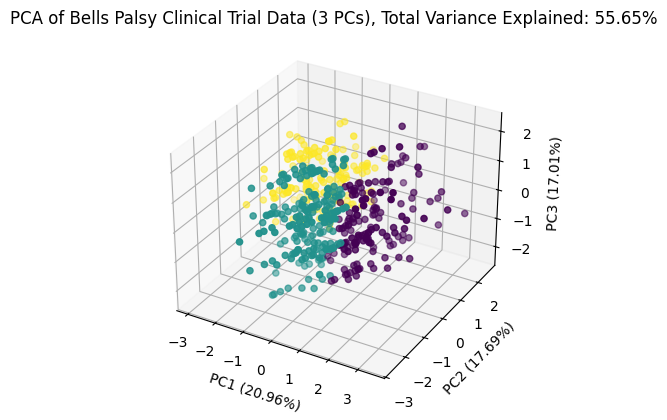

In [7]:
#PCA and KMeans Clustering with 3 Principal Components
pca = PCA(n_components = 3)
x_pca = pca.fit_transform(x_scaled)

kmeans = KMeans(n_clusters = 3, init = 'k-means++', random_state = 3)
labels = kmeans.fit_predict(x_pca)

variance_ratio = pca.explained_variance_ratio_
print(f"Variance Ratio of PC1: {variance_ratio[0]*100:.2f}%")
print(f"Variance Ratio of PC2: {variance_ratio[1]*100:.2f}%")
print(f"Variance Ratio of PC3: {variance_ratio[2]*100:.2f}%")
total_variance = sum(variance_ratio) * 100
print(f"Total Variance Explained by the 3 Principal Components: {total_variance:.2f}%")

#Plotting the Clusters
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(x_pca[:, 0], x_pca[:, 1], x_pca[:, 2], c=labels)

ax.set_xlabel(f"PC1 ({variance_ratio[0]*100:.2f}%)")
ax.set_ylabel(f"PC2 ({variance_ratio[1]*100:.2f}%)")
ax.set_zlabel(f"PC3 ({variance_ratio[2]*100:.2f}%)")
ax.set_title("PCA of Bells Palsy Clinical Trial Data (3 PCs), Total Variance Explained: {:.2f}%".format(total_variance))

#Analyzing the Cluster Characteristics with the 3-month and 9-month scores on the House–Brackmann scale
df['cluster'] = labels
print("===============================================")
print(pd.crosstab(df['cluster'], df['Baseline Score on House–Brackmann scale'], normalize='index'))
print("===============================================")
print(pd.crosstab(df['cluster'], df['3-Month Score on House–Brackmann scale'], normalize='index'))
print("===============================================")
print(pd.crosstab(df['cluster'], df['9-Month Score on House–Brackmann scale'], normalize='index'))

In [8]:
#Summary for PCA and KMeans Clustering with 2 Principal Components: each cluster
pred = pd.crosstab(df['cluster'], df['Received Prednisolone'], normalize='index')
acy = pd.crosstab(df['cluster'], df['Received Acyclovir'], normalize='index')
sex = pd.crosstab(df['cluster'], df['Sex'], normalize='index')
baseline = df.groupby('cluster')['Baseline Score on House–Brackmann scale'].mean()
Age = df.groupby('cluster')['Age'].mean()
rec3 = pd.crosstab(df['cluster'], df['Full Recovery in 3 Months'], normalize='index')
score3 = df.groupby('cluster')['3-Month Score on House–Brackmann scale'].mean()
rec9 = pd.crosstab(df['cluster'], df['Full Recovery in 9 Months'], normalize='index')
score9 = df.groupby('cluster')['9-Month Score on House–Brackmann scale'].mean()


for c in pred.index:
    print(f"Cluster {c}:")

    print(f"  Prednisolone     = Not received: {pred.loc[c, 0]*100:.1f}%, Received: {pred.loc[c, 1]*100:.1f}%")
    print(f"  Acyclovir        = Not received: {acy.loc[c, 0]*100:.1f}%, Received: {acy.loc[c, 1]*100:.1f}%")
    print(f"  Sex              = Female: {sex.loc[c, 0]*100:.1f}%, Male: {sex.loc[c, 1]*100:.1f}%")
    print(f"  Baseline Score   = {baseline[c]:.2f}")
    print(f"  Age              = {Age[c]:.2f}")
    print(f"Results:")
    print(f"  3-Month Recovery = Not recovered: {rec3.loc[c, 0]*100:.1f}%, Recovered: {rec3.loc[c, 1]*100:.1f}%")
    print(f"  3-Month Score    = {score3[c]:.2f}")
    print(f"  9-Month Recovery = Not recovered: {rec9.loc[c, 0]*100:.1f}%, Recovered: {rec9.loc[c, 1]*100:.1f}%")
    print(f"  9-Month Score    = {score9[c]:.2f}")

    print("--------------------------------------------------")

#Notes:
#K-means clustering separated groups based on increasing recovery rates at 3 and 9 months (Cluster 0 had lowest recovery rate, Cluster 2 had highest recovery rate)
#All clusters improved over time --> natural recovery time is important


Cluster 0:
  Prednisolone     = Not received: 70.3%, Received: 29.7%
  Acyclovir        = Not received: 58.9%, Received: 41.1%
  Sex              = Female: 70.3%, Male: 29.7%
  Baseline Score   = 4.56
  Age              = 54.93
Results:
  3-Month Recovery = Not recovered: 44.3%, Recovered: 55.7%
  3-Month Score    = 1.59
  9-Month Recovery = Not recovered: 18.4%, Recovered: 81.6%
  9-Month Score    = 1.28
--------------------------------------------------
Cluster 1:
  Prednisolone     = Not received: 63.5%, Received: 36.5%
  Acyclovir        = Not received: 43.9%, Received: 56.1%
  Sex              = Female: 27.5%, Male: 72.5%
  Baseline Score   = 3.23
  Age              = 38.22
Results:
  3-Month Recovery = Not recovered: 21.2%, Recovered: 78.8%
  3-Month Score    = 1.24
  9-Month Recovery = Not recovered: 7.9%, Recovered: 92.1%
  9-Month Score    = 1.09
--------------------------------------------------
Cluster 2:
  Prednisolone     = Not received: 8.2%, Received: 91.8%
  Acyclovir  